# Completed SPY Merton / LSTM project
Run cells in order. This notebook uses the packaged Python source, so its formulas and splits cannot drift from the CLI.

The historical calibration task and the next-21-session volatility forecasting task are separate. Results can be poor even when the code is correct. The supplied test set was previously examined; it is kept out of training here but is not a fresh scientific holdout.


In [1]:
from pathlib import Path
import sys, os, zipfile, importlib.util, tempfile
os.environ.setdefault("PIP_CACHE_DIR", str(Path(tempfile.gettempdir()) / "finance-pip-cache"))
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB:
    from google.colab import files
    uploaded = files.upload()  # Upload the COMPLETE project ZIP.
    names = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(names) != 1:
        raise ValueError("Upload exactly one complete project ZIP.")
    destination = Path("/content/completed_project").resolve()
    destination.mkdir(exist_ok=True)
    with zipfile.ZipFile(names[0]) as archive:
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(destination):
                raise ValueError("Unsafe ZIP member path.")
        archive.extractall(destination)
    roots = [p.parent for p in destination.rglob("run_project.py") if (p.parent / "config.json").exists()]
else:
    roots = [p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_project.py").exists()]
if len(roots) != 1:
    raise RuntimeError("Cannot identify the project. Start this notebook from the extracted project folder.")
ROOT = roots[0].resolve()
os.chdir(ROOT)
print("Project located. Raw data and source are available.")


Project located. Raw data and source are available.


In [2]:
import subprocess
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "torch==2.14.1",
                    "--index-url", "https://download.pytorch.org/whl/cpu"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"], check=True)
else:
    # Install requirements into this notebook's Python environment first (README).
    subprocess.run([sys.executable, "-m", "pip", "check"], check=True)
print("Using this notebook's Python environment.")


No broken requirements found.
Using this notebook's Python environment.


## Run from raw data
This recalibrates all historical windows, trains both model tasks, selects on validation, freezes choices and finally evaluates test dates. Forward labels crossing split boundaries are purged. No cached model or fit is reused.


In [3]:
subprocess.run([sys.executable, "run_project.py"], check=True)


2026-10-28 14:54:33,899 INFO Starting fresh calibration and model training; no cached fits or weights reused.
2026-10-28 14:54:33,928 INFO Chronological partitions: {'fit': {'n': 134, 'first_origin': '2019-08-01', 'last_origin': '2022-03-22', 'last_target_end': '2022-04-21'}, 'validation': {'n': 31, 'first_origin': '2022-04-27', 'last_origin': '2022-11-30', 'last_target_end': '2022-12-30'}, 'test': {'n': 46, 'first_origin': '2023-01-05', 'last_origin': '2023-11-28', 'last_target_end': '2023-12-28'}}
2026-10-28 14:54:33,946 INFO fit MLE 1/134


2026-10-28 14:54:34,488 INFO fit MLE 31/134


2026-10-28 14:54:34,938 INFO fit MLE 61/134


2026-10-28 14:54:35,521 INFO fit MLE 91/134


2026-10-28 14:54:36,121 INFO fit MLE 121/134


2026-10-28 14:54:36,374 INFO validation MLE 1/32


... (2 outputs left out)

2026-10-28 14:54:38,225 INFO Fitted volatility: Ridge alpha=100.0; LSTM units=16
2026-10-28 14:54:38,243 INFO Choices locked before test: {'parameter_model': 'persistence', 'parameter_scores': {'ridge': 1.805169142187663, 'lstm': 2.2361596429696844, 'mean': 3.429518673791823, 'persistence': 0.026774891320788013}, 'parameter_criterion': 'standardized transformed-parameter MSE', 'forecast_model': 'mle_total_vol', 'forecast_scores': {'training_mean': 0.07784762305986821, 'historical_21d': 0.06418456474449753, 'ewma': 0.058200819952434354, 'mle_total_vol': 0.056527723151967274, 'raw_mjd_total_vol': 0.05661627114565149, 'mean_total_vol': 0.11489593317124365, 'ridge_total_vol': 0.10424337002809415, 'lstm_total_vol': 0.11658611838639134, 'direct_ridge': 0.09112253869589272, 'direct_lstm': 0.07972397522739649}, 'forecast_criterion': 'next-H-session annualized volatility RMSE', 'models_frozen_before_test': True, 'test_used_for_tuning': False, 'prior_test_exposure': 'Supplied 2023 test results w

2026-10-28 14:54:38,834 INFO test MLE 31/47


2026-10-28 14:54:40,327 INFO Run complete in 7.13 seconds; captured warnings=0


CompletedProcess(args=['/private/tmp/finance-venv/bin/python', 'run_project.py'], returncode=0)

## Test and independently verify
Tests include mathematical identities, Poisson normalization, analytic gradients, parameter recovery on simulated data, date alignment, leakage, deterministic model reloads and a small end-to-end run. Verification recomputes forecasts and metrics from saved artifacts.


In [4]:
subprocess.run([sys.executable, "-m", "pytest", "-q"], check=True)
subprocess.run([sys.executable, "src/verify_project.py"], check=True)


.........

............

.....                                               [100%]
26 passed in 4.39s


Raw-file SHA256 hashes verified
Forward targets strictly precede the next split's first forecast origin
All saved scaler means recomputed from fit data only
Prediction/reference dates and source rows match raw observations
Future labels independently recomputed from t+1 through t+H
Saved Ridge/LSTM/mean inference matches all prediction CSVs
Inference is deterministic
Parameter and future-volatility metrics independently recompute
Every calibration has a successful start and an adequate Poisson truncation
Saved example prediction reproduces exactly
No runtime warnings captured


CompletedProcess(args=['/private/tmp/finance-venv/bin/python', 'src/verify_project.py'], returncode=0)

,split,model,n,MAE,RMSE,bias,R2,R2_oos,correlation,error_q05,error_q50,error_q95,undefined_reason
10,test,training_mean,46,0.056934,0.063378,0.056924,-4.173438,-3.731434,NaN,0.009099,0.063428,0.094308,correlation: constant series
11,test,historical_21d,46,0.023669,0.029137,0.006252,-0.093419,0.000000,0.487172,-0.033503,0.005034,0.058682,NaN
12,test,ewma,46,0.024097,0.028179,0.009395,-0.022756,0.064625,0.554553,-0.027611,0.012280,0.053409,NaN
13,test,mle_total_vol,46,0.044278,0.050488,0.036432,-2.283050,-2.002556,0.606007,-0.029543,0.046802,0.084432,NaN
14,test,raw_mjd_total_vol,46,0.044577,0.050878,0.036738,-2.334080,-2.049225,0.608174,-0.029537,0.046922,0.084565,NaN
15,test,mean_total_vol,46,0.027362,0.031435,0.014552,-0.272726,-0.163988,NaN,-0.033273,0.021056,0.051936,correlation: constant series
16,test,ridge_total_vol,46,0.030913,0.034349,0.010317,-0.519650,-0.389816,-0.285227,-0.040570,0.016073,0.050164,NaN
17,test,lstm_total_vol,46,0.025338,0.029806,0.009660,-0.144219,-0.046460,0.068342,-0.035770,0.008871,0.052122,NaN
18,test,direct_ridge,46,0.024167,0.028088,0.009254,-0.016106,0.070707,0.388840,-0.041585,0.012559,0.044472,NaN
19,test,direct_lstm,46,0.023191,0.026553,0.010763,0.091902,0.169487,0.504867,-0.034802,0.018444,0.038760,NaN


,split,model,target,n,MAE,RMSE,bias,R2,R2_oos,correlation,error_q05,error_q50,error_q95,undefined_reason
0,validation,ridge,mu_log,31,0.001696,0.001842,0.001696,-9.338644,0.553000,0.538696,7.061531e-04,0.001703,0.002782,NaN
1,validation,ridge,sigma,31,0.005962,0.006083,-0.005962,-34.882528,0.373868,0.324060,-7.838579e-03,-0.005849,-0.004265,NaN
2,validation,ridge,lambda,31,0.045130,0.058549,0.045130,NaN,0.838042,NaN,5.576556e-03,0.026780,0.119709,correlation: constant series; R2: constant ref...
3,validation,ridge,mu_j,31,0.009811,0.011525,0.009740,NaN,-0.780665,NaN,1.089835e-03,0.009241,0.020205,correlation: constant series; R2: constant ref...
4,validation,ridge,sigma_j,31,0.002943,0.003354,0.002943,NaN,0.797574,NaN,8.211390e-04,0.002963,0.005693,correlation: constant series; R2: constant ref...
5,validation,lstm,mu_log,31,0.002260,0.002327,0.002260,-15.489207,0.287075,0.436440,1.342193e-03,0.002201,0.003118,NaN
6,validation,lstm,sigma,31,0.006667,0.006779,-0.006667,-43.563371,0.222392,0.105493,-8.741577e-03,-0.006754,-0.004537,NaN
7,validation,lstm,lambda,31,0.050619,0.053686,0.050619,NaN,0.863829,NaN,1.757180e-02,0.053049,0.072963,correlation: constant series; R2: constant ref...
8,validation,lstm,mu_j,31,0.003411,0.004068,0.003405,NaN,0.778198,NaN,2.197009e-04,0.003180,0.007038,correlation: constant series; R2: constant ref...
9,validation,lstm,sigma_j,31,0.003743,0.004083,0.003743,NaN,0.699998,NaN,1.775991e-03,0.003465,0.006846,correlation: constant series; R2: constant ref...


# SPY Merton calibration and future-volatility evaluation

This project estimates a historical physical-measure return distribution and learns an approximation to that calibration. A separate supervised task predicts future realized volatility. Neither task predicts prices or establishes trading profitability.

## Method

Use the supplied chronological CSVs unchanged. Recompute decimal log returns from Close. Exclude only the first price-only row, whose preceding close is unavailable. The raw adjustment/dividend policy cannot be independently established. Features are known after the forecast-origin close.

Calibrate the exact compound-Poisson normal mixture on 126 past observed returns at stride 5. Use scaled multistart constrained MLE, analytic derivatives, log-sum-exp and a Poisson tail tolerance of 1e-12. Preserve all raw fits and optimizer attempts. Compare the full five-parameter fit to an exact two-parameter Gaussian with BIC. The latter admits lambda=0 and records unused jump parameters as canonical zeros. BIC in this boundary mixture is a model-selection heuristic, not a formal jump test. Canonical zeros do not prove a zero-sized jump distribution.

Train mean, tuned Ridge and small LSTM models on the selected historical reference parameters. The LSTM uses 21 returns and absolute returns plus historical summary statistics. The reference parameters are estimated labels, not ground truth. Direct Ridge/LSTM volatility models use the same historical inputs and the actual following 21 returns as targets. Positive predictions use documented output links, with no post-prediction clipping.

Each future label is a demeaned sample SD with ddof=1, multiplied by sqrt(252). Model total volatility is sqrt(A*(sigma² + lambda*(mu_j² + sigma_j²))). These are compatible variance targets; expected sample SD need not equal the square root of expected variance. Parameter constancy across a future horizon is only a proxy assumption.

Fit/validation/test sizes: 134/31/46. Purge forward labels that cross the next partition's first forecast origin. Historical feature windows may overlap across partitions because that history was already known. Preprocessing uses fit samples only. Checkpoints, regularization and model family are selected on validation; models then freeze.

## Actual test results

Forecast model selected on validation: **mle_total_vol**. It did not improve the historical-volatility baseline on this fixed test rerun. Selection was not changed after observing these results. R2_oos uses historical_21d as the declared benchmark; ordinary R2 uses the evaluation sample mean and is saved separately.

| model | n | MAE | RMSE | bias | R2_oos |
| --- | --- | --- | --- | --- | --- |
| direct_lstm | 46 | 0.023191 | 0.026553 | 0.010763 | 0.169487 |
| direct_ridge | 46 | 0.024167 | 0.028088 | 0.009254 | 0.070707 |
| ewma | 46 | 0.024097 | 0.028179 | 0.009395 | 0.064625 |
| historical_21d | 46 | 0.023669 | 0.029137 | 0.006252 | 0.000000 |
| lstm_total_vol | 46 | 0.025338 | 0.029806 | 0.009660 | -0.046460 |
| mean_total_vol | 46 | 0.027362 | 0.031435 | 0.014552 | -0.163988 |
| ridge_total_vol | 46 | 0.030913 | 0.034349 | 0.010317 | -0.389816 |
| mle_total_vol | 46 | 0.044278 | 0.050488 | 0.036432 | -2.002556 |
| raw_mjd_total_vol | 46 | 0.044577 | 0.050878 | 0.036738 | -2.049225 |
| training_mean | 46 | 0.056934 | 0.063378 | 0.056924 | -3.731434 |

Errors are prediction minus observation. Decimal 0.01 is one annualized volatility percentage point. Full per-parameter results and reconstructed historical total-volatility results are in results/metrics. Correlation is undefined for a constant series; blank metric cells have explicit reasons, not unhandled missing values.

## Numerical and statistical limitations

Raw five-parameter fits at bounds: 165/211. BIC selected a jump component in 69/211 windows. Failed optimizer starts (including nonselected starts) total 0; every attempt is retained. No window is dropped for poor fit or poor forecast performance.

Longer windows reduce small-sample instability but mix changing volatility regimes. Adjacent windows and 21-session future targets overlap. These metrics are descriptive; no IID confidence interval or significance claim is made. A nonoverlapping subsequence sensitivity table is included, but its smaller sample still does not establish deployment reliability. The dataset is too small for strong deep-learning conclusions.

The supplied 2023 test results had already been examined in the original project. This repair keeps them out of fitting, scaling and tuning, but cannot turn them into genuinely unseen data. A new future dataset is needed for a fresh scientific holdout. No raw data were replaced and no scores were manufactured.

## Reproduction

Run `python run_project.py`, `python -m pytest -q`, and `python src/verify_project.py`. Saved weights and preprocessing reproduce inference exactly in the tested environment. The manifest records versions, partitions and raw hashes. The CLI and notebook share source modules. A hosted Google Colab service session and the guide's optional live option comparison are not executed here. The source runs offline after dependency installation.


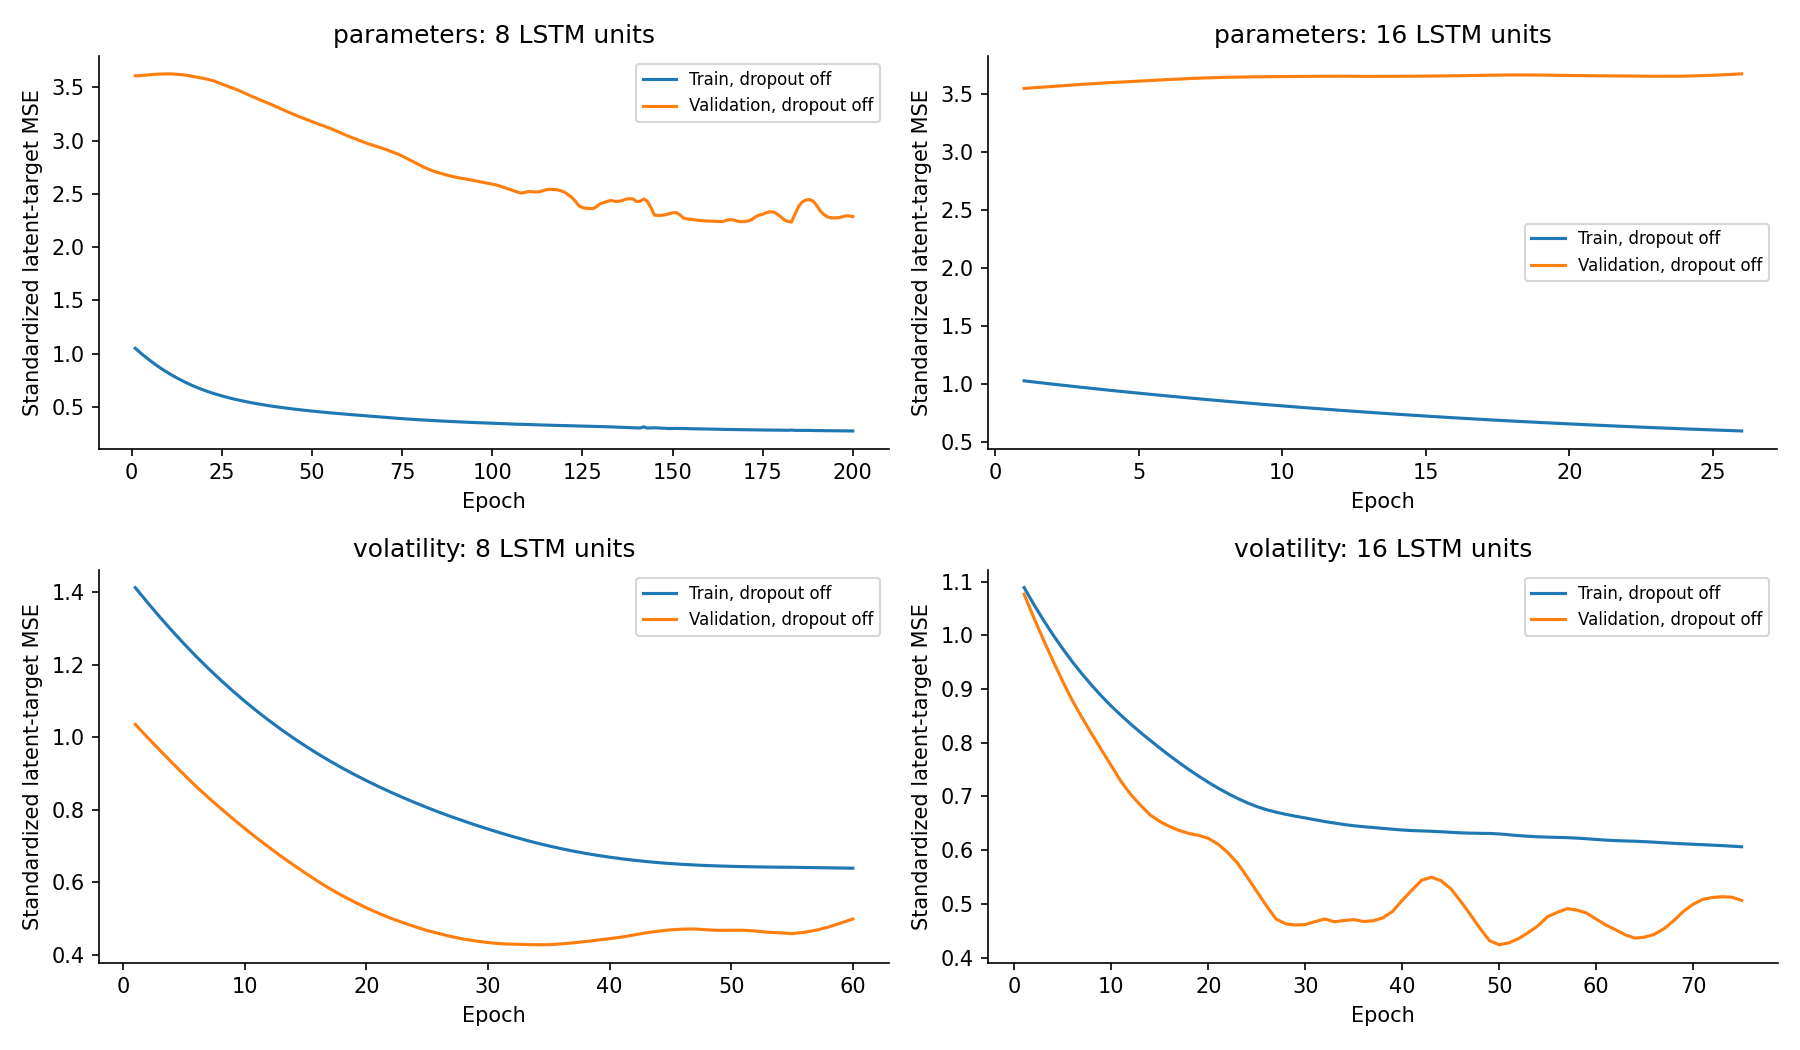

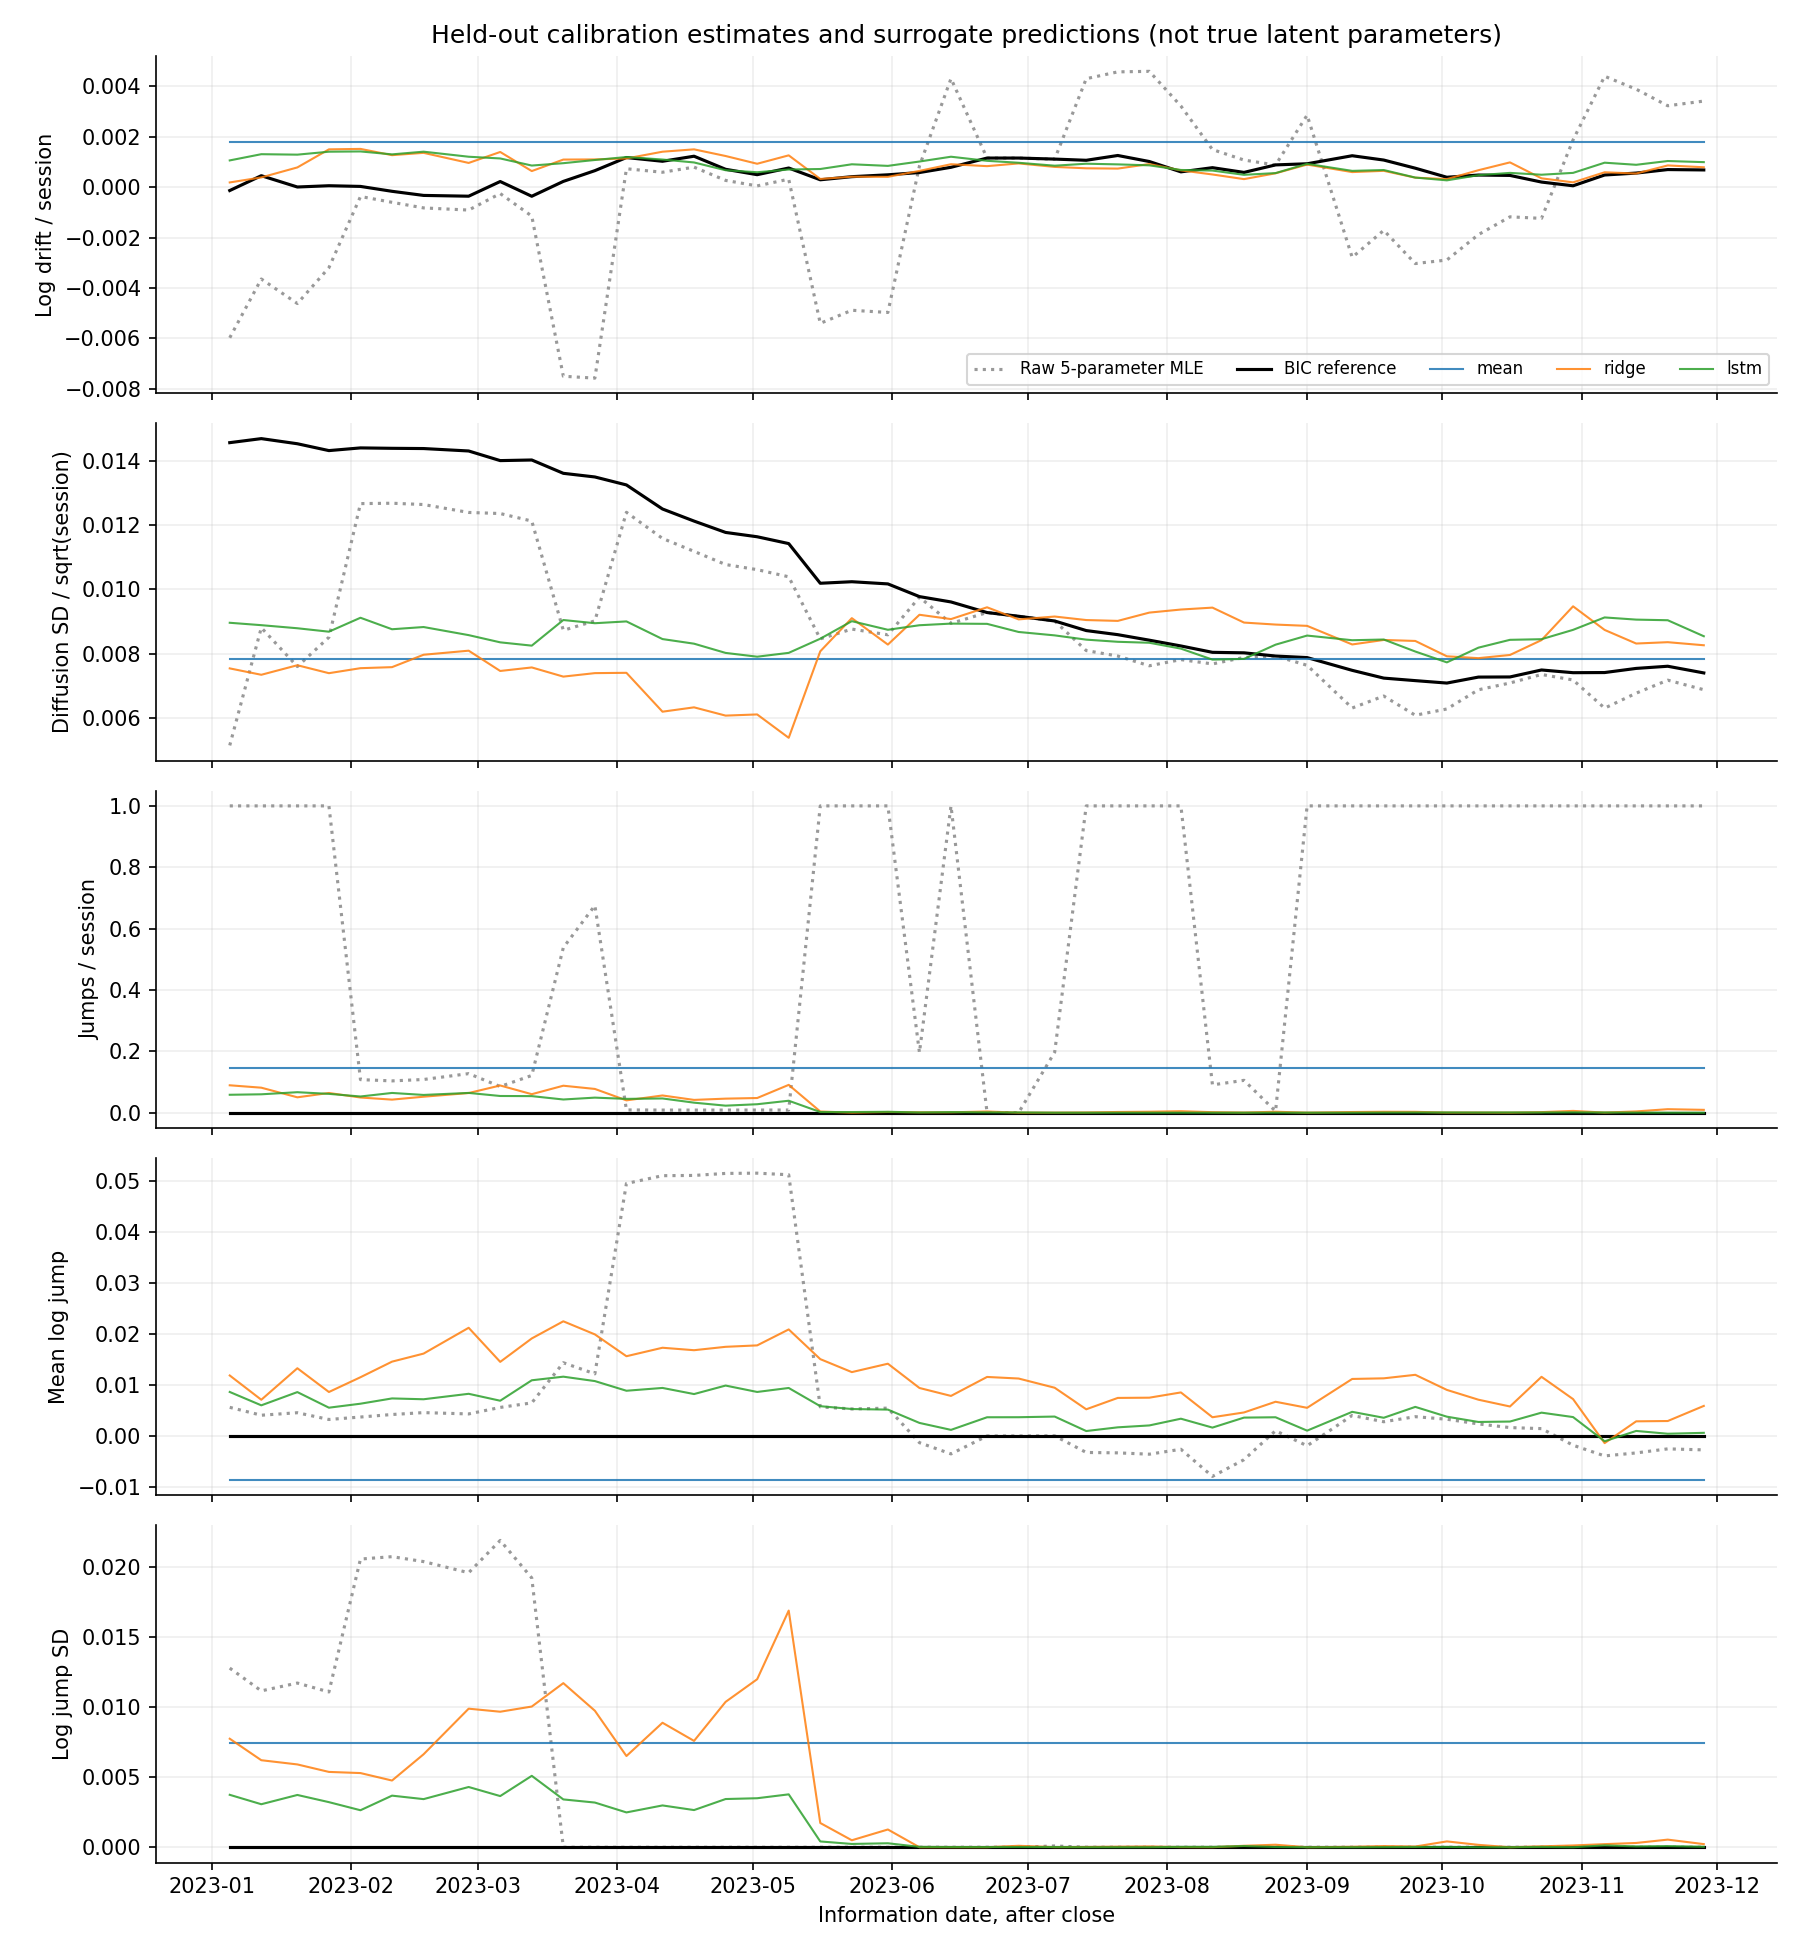

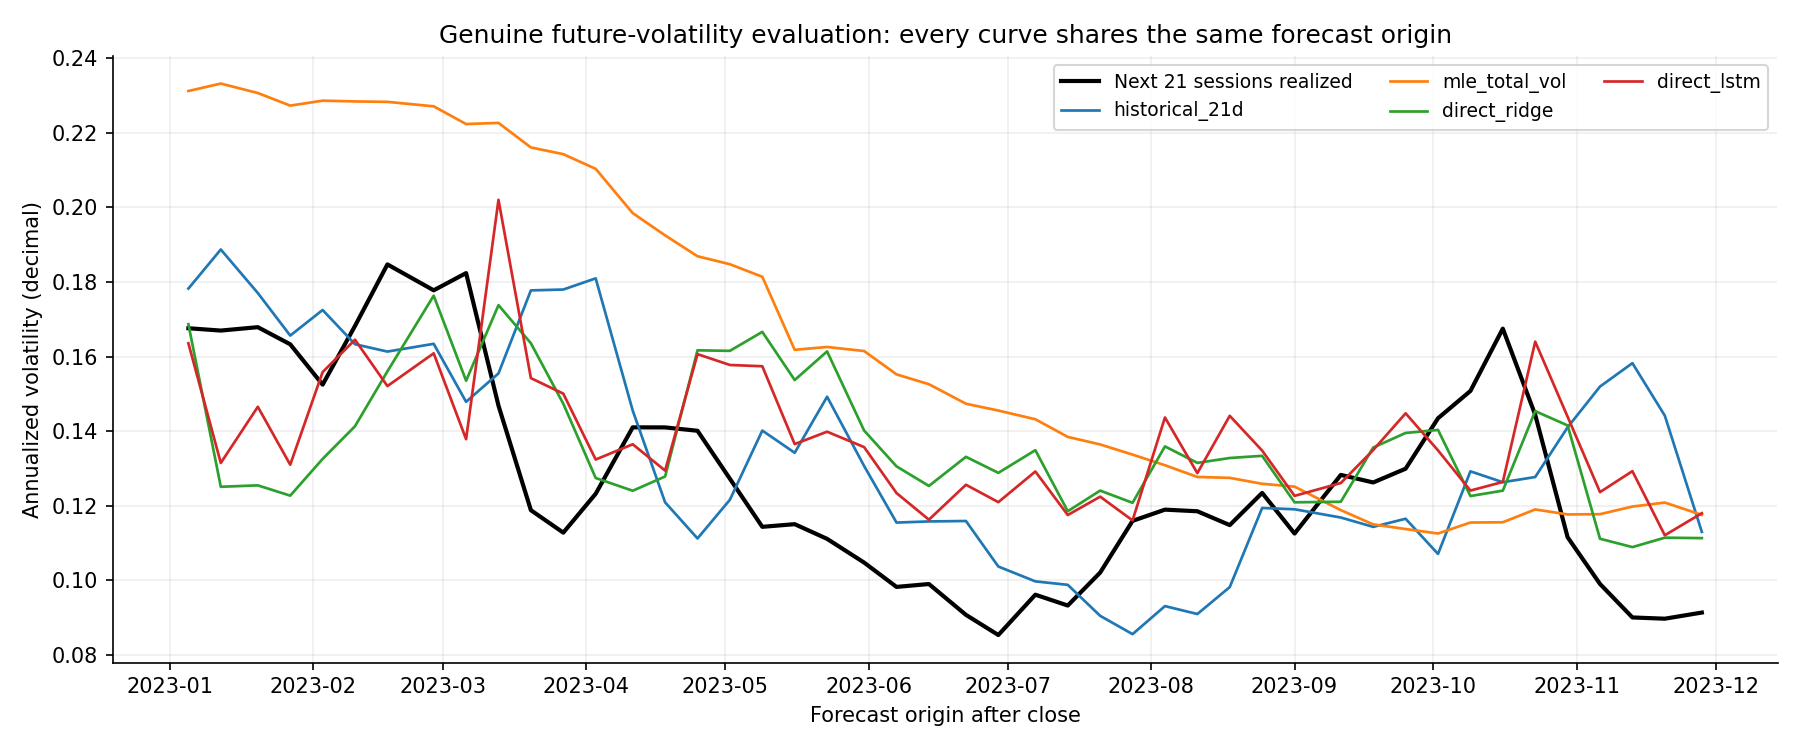

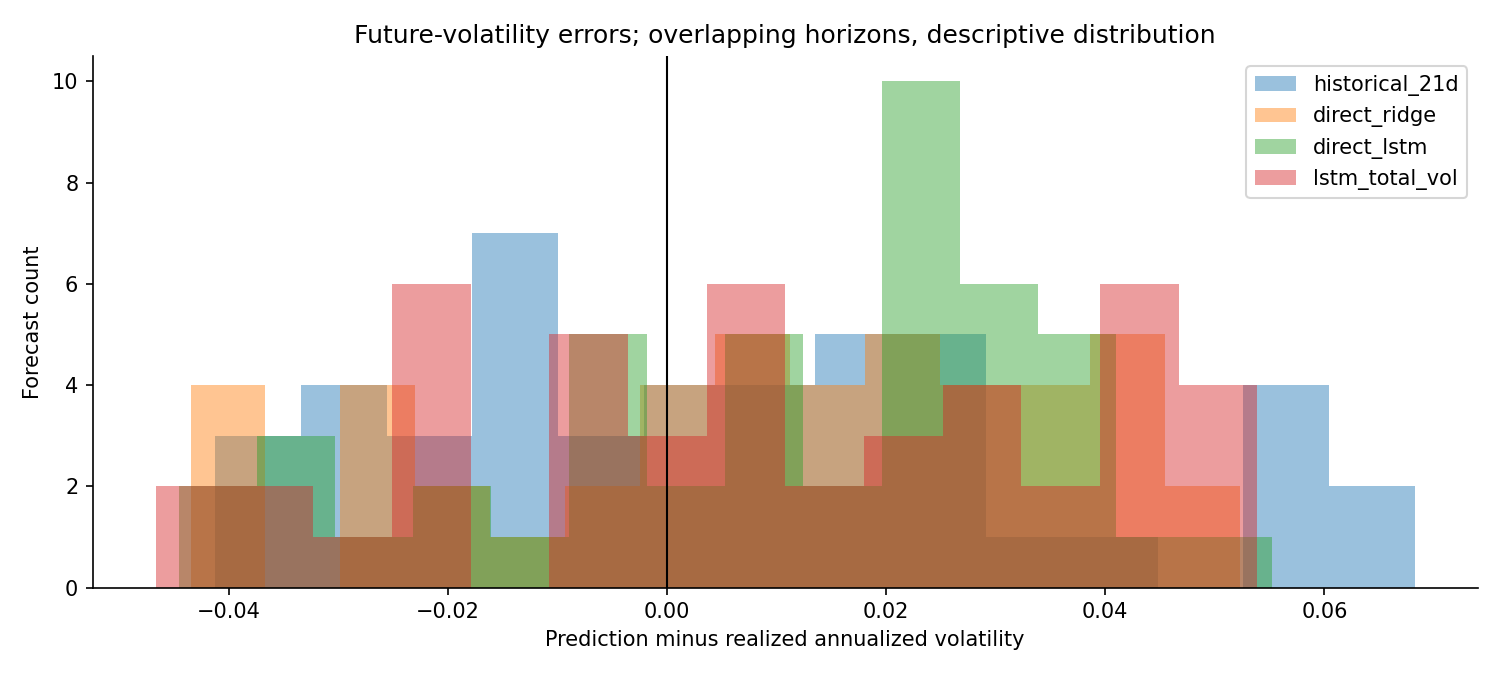

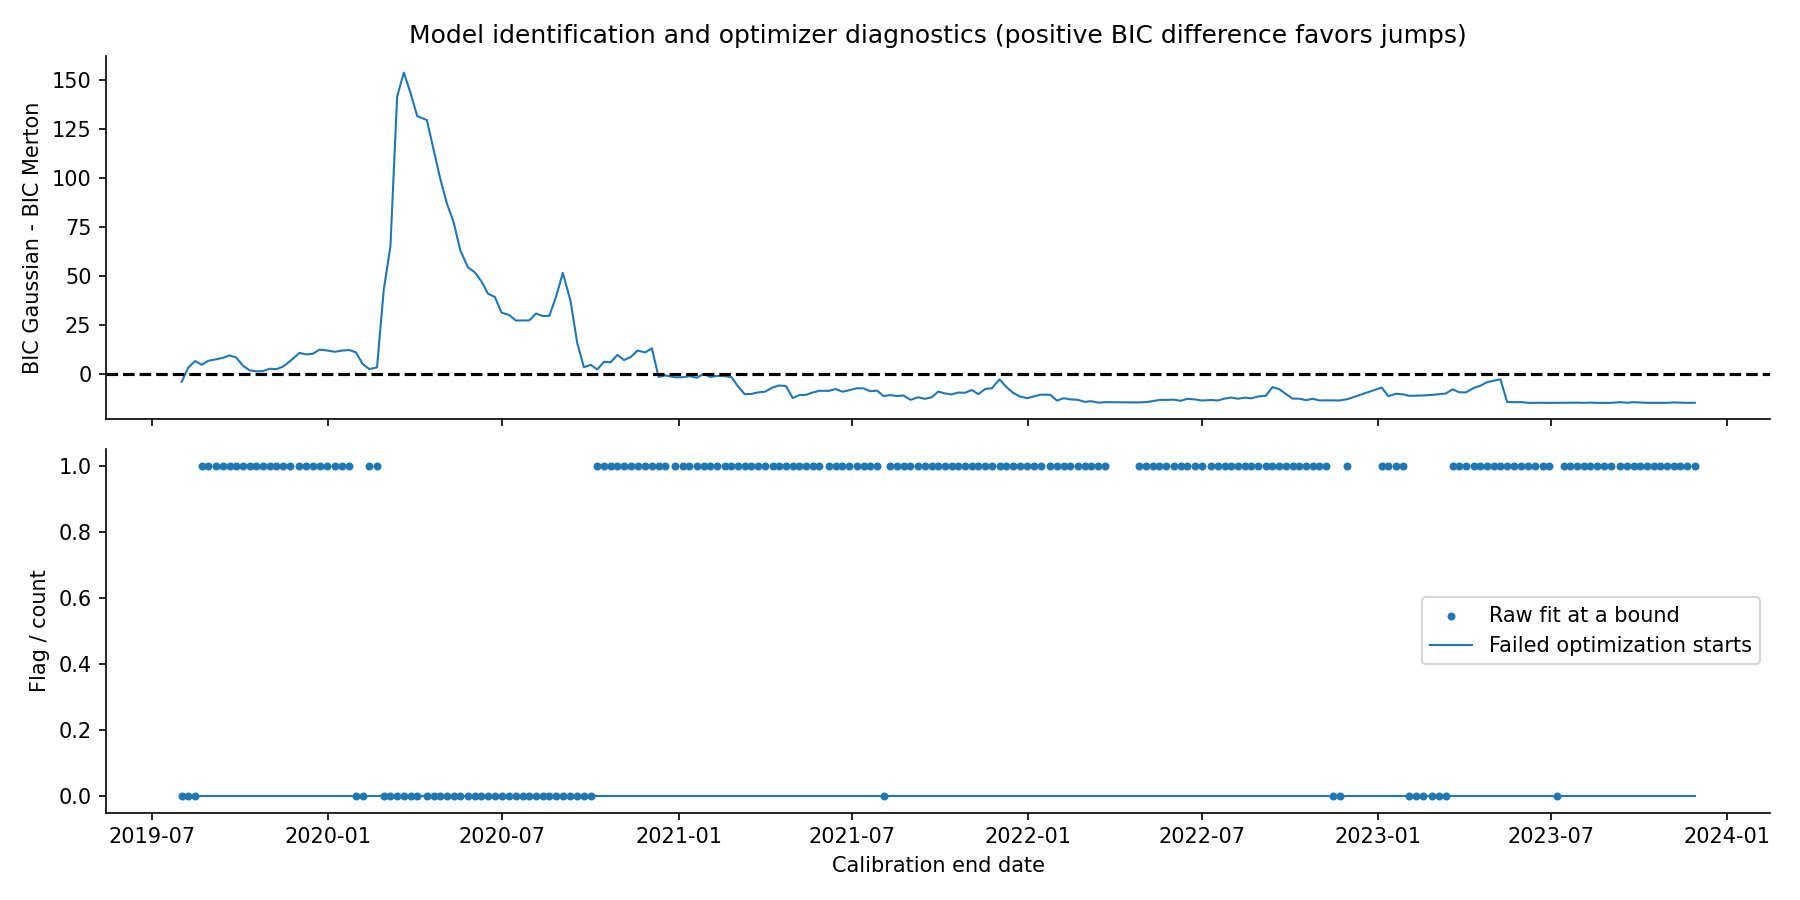

In [5]:
import pandas as pd
from IPython.display import display, Markdown, Image
metrics = pd.read_csv("results/metrics/future_volatility.csv")
display(metrics[metrics["split"] == "test"])
display(pd.read_csv("results/metrics/parameter_metrics.csv"))
display(Markdown(Path("report/project_summary.md").read_text()))
for name in ["training", "parameters", "future_volatility", "errors", "calibration_diagnostics"]:
    display(Image(filename=f"results/figures/{name}.png"))


## Reload and predict
The saved example includes all historical returns needed to reconstruct sequence, summary and EWMA features. It uses no future prices.


In [6]:
sys.path.insert(0, str(ROOT / "src"))
from finance_project.pipeline import example_predict
print(example_predict(ROOT))


{'date': '2023-01-05', 'lstm_parameters': {'mu_log': 0.0010659282561391592, 'sigma': 0.008963979962245634, 'lambda': 0.05840964554405326, 'mu_j': 0.008635319769382477, 'sigma_j': 0.0037480883602232368}, 'direct_lstm_future_volatility': 0.16356387734413147}


## Save the completed run
In Colab this downloads a backup ZIP. Locally the folder already contains every result. Preserve the complete folder, including model preprocessing files.


In [7]:
if IN_COLAB:
    backup = ROOT.parent / "finance_project_completed_backup.zip"
    with zipfile.ZipFile(backup, "w", zipfile.ZIP_DEFLATED) as archive:
        for path in ROOT.rglob("*"):
            if path.is_file() and not any(part in {".venv", "__pycache__", ".pytest_cache", ".ipynb_checkpoints"} for part in path.relative_to(ROOT).parts):
                archive.write(path, Path(ROOT.name) / path.relative_to(ROOT))
    files.download(str(backup))
else:
    print("Completed results are saved in this project folder.")


Completed results are saved in this project folder.
